<a href="https://colab.research.google.com/github/jaquelopxs/Algoritmos-de-busca/blob/main/Atividade_identificar_dog.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ==========================================
# 1. INSTALAÇÃO E IMPORTAÇÃO
# ==========================================

!pip install -q tensorflow torch torchvision scikit-learn matplotlib seaborn pillow

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image
from io import BytesIO
import requests

import tensorflow as tf
from tensorflow.keras import layers, models

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
torch.manual_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("TensorFlow:", tf.__version__)
print("PyTorch:", torch.__version__)
print("Dispositivo:", device)



TensorFlow: 2.21.0
PyTorch: 2.14.1+cu130
Dispositivo: cuda


In [ ]:
# ==========================================
# 2. GOOGLE DRIVE
# ==========================================

from google.colab import drive

drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/Sistemas Inteligentes'

CHIHUAHUA_DIR = os.path.join(BASE_DIR, 'chihuahua')
MUFFIN_DIR = os.path.join(BASE_DIR, 'muffin')

print("Pastas encontradas com sucesso!")

Mounted at /content/drive
Pastas encontradas com sucesso!


In [ ]:
# ==========================================
# 3. CARREGAMENTO DOS ARQUIVOS
# ==========================================

EXTENSOES = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

arquivos = []
rotulos = []

for classe, pasta in enumerate([CHIHUAHUA_DIR, MUFFIN_DIR]):

    for nome in os.listdir(pasta):

        if nome.lower().endswith(EXTENSOES):

            caminho = os.path.join(pasta, nome)

            try:
                with Image.open(caminho) as img:
                    img.verify()

                arquivos.append(caminho)
                rotulos.append(classe)

            except Exception:
                print("Imagem ignorada:", caminho)

arquivos = np.array(arquivos)
rotulos = np.array(rotulos)

print("Total de imagens:", len(arquivos))
print("Chihuahua:", np.sum(rotulos == 0))
print("Muffin:", np.sum(rotulos == 1))

assert len(arquivos) > 0, "Nenhuma imagem encontrada!"
assert len(np.unique(rotulos)) == 2, "As duas classes precisam ter imagens!"
assert min(np.bincount(rotulos)) >= 3, "Cada classe precisa ter pelo menos 3 imagens."

Total de imagens: 1395
Chihuahua: 895
Muffin: 500


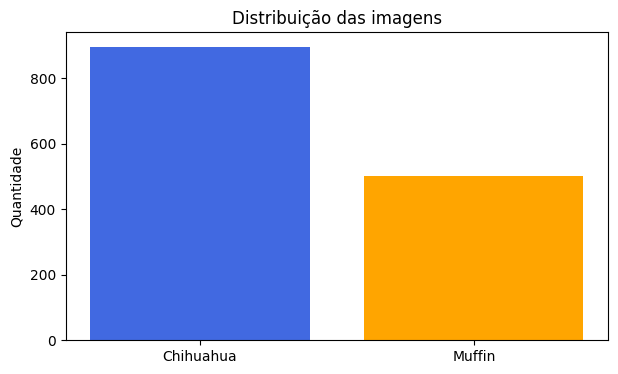

In [ ]:
# ==========================================
# 4. DISTRIBUIÇÃO DAS CLASSES
# ==========================================

contagem = [
    np.sum(rotulos == 0),
    np.sum(rotulos == 1)
]

plt.figure(figsize=(7, 4))

plt.bar(
    ['Chihuahua', 'Muffin'],
    contagem,
    color=['royalblue', 'orange']
)

plt.title('Distribuição das imagens')
plt.ylabel('Quantidade')
plt.show()

In [ ]:
# ==========================================
# 5. DIVISÃO DOS DADOS
# ==========================================

X_train, X_temp, y_train, y_temp = train_test_split(
    arquivos,
    rotulos,
    test_size=0.30,
    random_state=SEED,
    stratify=rotulos
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Treinamento:", len(X_train))
print("Validação:", len(X_val))
print("Teste:", len(X_test))

Treinamento: 976
Validação: 209
Teste: 210


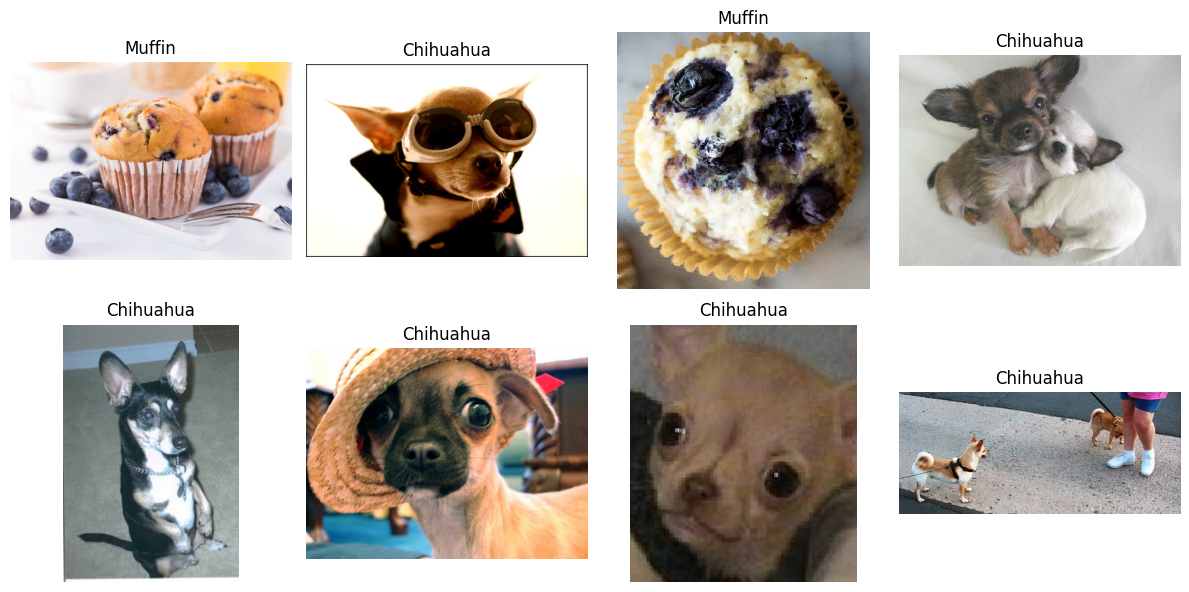

In [ ]:
# ==========================================
# 6. EXEMPLOS DA BASE
# ==========================================

plt.figure(figsize=(12, 6))

indices = np.random.choice(
    len(arquivos),
    min(8, len(arquivos)),
    replace=False
)

for i, idx in enumerate(indices):

    img = Image.open(arquivos[idx]).convert('RGB')

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(
        'Muffin' if rotulos[idx] == 1 else 'Chihuahua'
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 7. PREPARAÇÃO DOS DADOS PARA TENSORFLOW
# ==========================================

IMG_SIZE = (64, 64)
BATCH_SIZE = 32

def carregar_imagem_tf(caminho, rotulo):

    imagem = tf.io.read_file(caminho)

    imagem = tf.io.decode_image(
        imagem,
        channels=3,
        expand_animations=False
    )

    imagem.set_shape([None, None, 3])

    imagem = tf.image.resize(imagem, IMG_SIZE)

    imagem = tf.cast(imagem, tf.float32) / 255.0

    return imagem, tf.cast(rotulo, tf.float32)


def criar_dataset(X, y, treino=False):

    ds = tf.data.Dataset.from_tensor_slices((X, y))

    ds = ds.map(
        carregar_imagem_tf,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if treino:
        ds = ds.shuffle(len(X), seed=SEED)

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_tf = criar_dataset(X_train, y_train, True)
val_tf = criar_dataset(X_val, y_val)
test_tf = criar_dataset(X_test, y_test)

In [ ]:

# ==========================================
# 8. CNN COM KERAS
# ==========================================

model_tf = models.Sequential([

    layers.Input(shape=(64, 64, 3)),

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),

    layers.Dense(1, activation='sigmoid')
])

model_tf.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_tf.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 683,329 (2.61 MB)

 Trainable params: 683,329 (2.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==========================================
# 9. TREINAMENTO TENSORFLOW
# ==========================================

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    )
]

history_tf = model_tf.fit(
    train_tf,
    validation_data=val_tf,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 30s 409ms/step - accuracy: 0.6506 - loss: 0.6281 - val_accuracy: 0.7943 - val_loss: 0.4769
Epoch 2/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.7705 - loss: 0.5002 - val_accuracy: 0.7656 - val_loss: 0.4182
Epoch 3/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 11s 92ms/step - accuracy: 0.8412 - loss: 0.3679 - val_accuracy: 0.8804 - val_loss: 0.2794
Epoch 4/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 10s 103ms/step - accuracy: 0.8811 - loss: 0.2926 - val_accuracy: 0.8038 - val_loss: 0.4543
Epoch 5/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 10s 93ms/step - accuracy: 0.8832 - loss: 0.2883 - val_accuracy: 0.8995 - val_loss: 0.2544
Epoch 6/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 9s 62ms/step - accuracy: 0.9057 - loss: 0.2411 - val_accuracy: 0.8995 - val_loss: 0.2843
Epoch 7/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 9s 103ms/step - accuracy: 0.9150 - loss: 0.2281 - val_accuracy: 0.9043 - val_loss: 0.2626
Epoch 8/20
31/31 ━━━━━━━━━━━━━━━━━━━━ 9s 62ms/step - accuracy: 0.9150 - loss: 0.2189 - val_accuracy: 0.

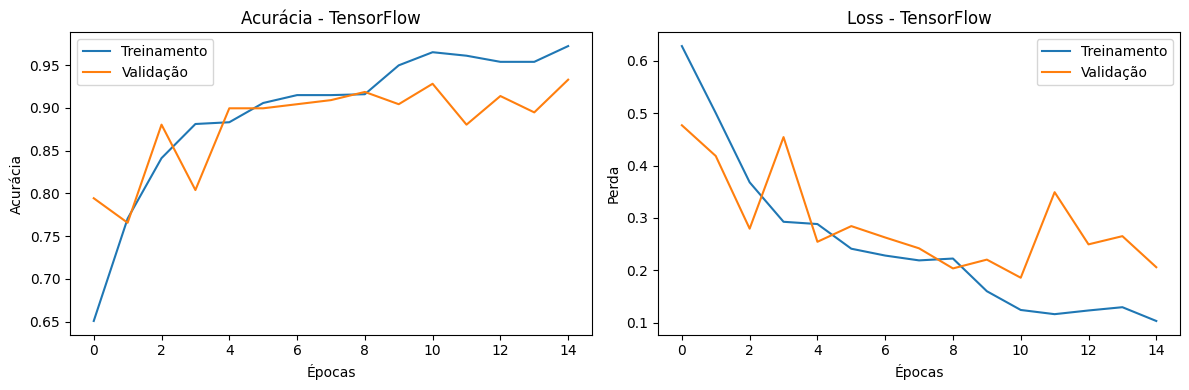

In [ ]:
# ==========================================
# 10. RESULTADOS TENSORFLOW
# ==========================================

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history_tf.history['accuracy'], label='Treinamento')
plt.plot(history_tf.history['val_accuracy'], label='Validação')

plt.title('Acurácia - TensorFlow')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history_tf.history['loss'], label='Treinamento')
plt.plot(history_tf.history['val_loss'], label='Validação')

plt.title('Loss - TensorFlow')
plt.xlabel('Épocas')
plt.ylabel('Perda')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 11. PREPARAÇÃO DOS DADOS PARA PYTORCH
# ==========================================

transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])


class ChihuahuaMuffinDataset(Dataset):

    def __init__(self, caminhos, rotulos):

        self.caminhos = caminhos
        self.rotulos = rotulos

    def __len__(self):
        return len(self.caminhos)

    def __getitem__(self, idx):

        imagem = Image.open(
            self.caminhos[idx]
        ).convert('RGB')

        imagem = transform(imagem)

        rotulo = torch.tensor(
            self.rotulos[idx],
            dtype=torch.float32
        )

        return imagem, rotulo


train_pt = ChihuahuaMuffinDataset(X_train, y_train)
val_pt = ChihuahuaMuffinDataset(X_val, y_val)
test_pt = ChihuahuaMuffinDataset(X_test, y_test)

train_loader = DataLoader(
    train_pt,
    batch_size=32,
    shuffle=True
)

val_loader = DataLoader(
    val_pt,
    batch_size=32,
    shuffle=False
)

test_loader = DataLoader(
    test_pt,
    batch_size=32,
    shuffle=False
)

In [ ]:
# ==========================================
# 12. CNN COM PYTORCH
# ==========================================

class CNN_PyTorch(nn.Module):

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3, 32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(128 * 6 * 6, 128),
            nn.ReLU(),

            nn.Dropout(0.4),

            nn.Linear(128, 1)
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x.squeeze(1)


model_pt = CNN_PyTorch().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = optim.Adam(
    model_pt.parameters(),
    lr=0.001
)

print(model_pt)

CNN_PyTorch(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4608, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.4, inplace=False)
    (4): Linear(in_features=128, out_features=1, bias=True)
  )
)


In [ ]:
# ==========================================
# 13. TREINAMENTO PYTORCH
# ==========================================

EPOCHS = 20

history_pt = {
    'loss': [],
    'val_loss': [],
    'accuracy': [],
    'val_accuracy': []
}

best_val_loss = float('inf')
best_weights = None
patience = 4
epochs_without_improvement = 0

for epoch in range(EPOCHS):

    model_pt.train()

    total_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model_pt(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        total_loss += loss.item() * labels.size(0)

        predictions = (torch.sigmoid(outputs) >= 0.5).float()

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / total
    train_acc = correct / total

    # Validação
    model_pt.eval()

    val_loss_total = 0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_pt(images)

            loss = criterion(outputs, labels)

            val_loss_total += loss.item() * labels.size(0)

            predictions = (
                torch.sigmoid(outputs) >= 0.5
            ).float()

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = val_loss_total / val_total
    val_acc = val_correct / val_total

    history_pt['loss'].append(train_loss)
    history_pt['accuracy'].append(train_acc)

    history_pt['val_loss'].append(val_loss)
    history_pt['val_accuracy'].append(val_acc)

    print(
        f"Época {epoch+1}/{EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Acurácia: {train_acc:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:

        best_val_loss = val_loss

        best_weights = {
            k: v.detach().cpu().clone()
            for k, v in model_pt.state_dict().items()
        }

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:

        print("Early stopping ativado.")
        break

if best_weights is not None:
    model_pt.load_state_dict(best_weights)

print("Treinamento PyTorch concluído!")

Época 1/20 | Loss: 0.6234 | Acurácia: 0.6752 | Val Loss: 0.5903 | Val Acc: 0.6842
Época 2/20 | Loss: 0.4973 | Acurácia: 0.7828 | Val Loss: 0.3655 | Val Acc: 0.8756
Época 3/20 | Loss: 0.4047 | Acurácia: 0.8299 | Val Loss: 0.4333 | Val Acc: 0.7703
Época 4/20 | Loss: 0.3839 | Acurácia: 0.8432 | Val Loss: 0.2742 | Val Acc: 0.9234
Época 5/20 | Loss: 0.3243 | Acurácia: 0.8668 | Val Loss: 0.2590 | Val Acc: 0.9234
Época 6/20 | Loss: 0.3005 | Acurácia: 0.8852 | Val Loss: 0.2814 | Val Acc: 0.9139
Época 7/20 | Loss: 0.2966 | Acurácia: 0.8791 | Val Loss: 0.2360 | Val Acc: 0.9234
Época 8/20 | Loss: 0.2897 | Acurácia: 0.8842 | Val Loss: 0.2765 | Val Acc: 0.8804
Época 9/20 | Loss: 0.2847 | Acurácia: 0.8873 | Val Loss: 0.2181 | Val Acc: 0.9139
Época 10/20 | Loss: 0.2322 | Acurácia: 0.9201 | Val Loss: 0.2297 | Val Acc: 0.9043
Época 11/20 | Loss: 0.2394 | Acurácia: 0.8975 | Val Loss: 0.2533 | Val Acc: 0.8804
Época 12/20 | Loss: 0.2535 | Acurácia: 0.8986 | Val Loss: 0.2095 | Val Acc: 0.8995
Época 13/20 |

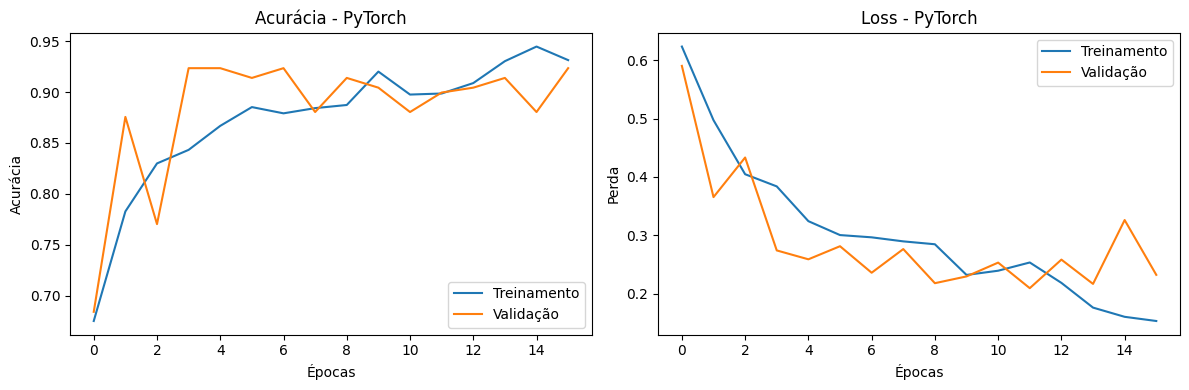

In [ ]:
# ==========================================
# 14. RESULTADOS PYTORCH
# ==========================================

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)

plt.plot(history_pt['accuracy'], label='Treinamento')
plt.plot(history_pt['val_accuracy'], label='Validação')

plt.title('Acurácia - PyTorch')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(history_pt['loss'], label='Treinamento')
plt.plot(history_pt['val_loss'], label='Validação')

plt.title('Loss - PyTorch')
plt.xlabel('Épocas')
plt.ylabel('Perda')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 15. PREVISÕES DOS DOIS MODELOS
# ==========================================

# TensorFlow
y_prob_tf = model_tf.predict(test_tf, verbose=0).ravel()

y_pred_tf = (y_prob_tf >= 0.5).astype(int)

# PyTorch
model_pt.eval()

y_prob_pt = []
y_pred_pt = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model_pt(images)

        probabilities = torch.sigmoid(outputs)

        predictions = (probabilities >= 0.5).int()

        y_prob_pt.extend(
            probabilities.cpu().numpy()
        )

        y_pred_pt.extend(
            predictions.cpu().numpy()
        )

y_pred_pt = np.array(y_pred_pt).astype(int)

# Conferência
print("Quantidade de imagens de teste:", len(y_test))
print("Previsões TensorFlow:", len(y_pred_tf))
print("Previsões PyTorch:", len(y_pred_pt))

Quantidade de imagens de teste: 210
Previsões TensorFlow: 210
Previsões PyTorch: 210


In [ ]:
# ==========================================
# 16. MÉTRICAS COM SCIKIT-LEARN
# ==========================================

def avaliar_modelo(nome, y_real, y_pred):

    resultados = {
        'Modelo': nome,

        'Acurácia': accuracy_score(
            y_real, y_pred
        ),

        'Precisão': precision_score(
            y_real, y_pred, zero_division=0
        ),

        'Recall': recall_score(
            y_real, y_pred, zero_division=0
        ),

        'F1-score': f1_score(
            y_real, y_pred, zero_division=0
        )
    }

    return resultados


resultado_tf = avaliar_modelo(
    'TensorFlow/Keras',
    y_test,
    y_pred_tf
)

resultado_pt = avaliar_modelo(
    'PyTorch',
    y_test,
    y_pred_pt
)

tabela_resultados = pd.DataFrame([
    resultado_tf,
    resultado_pt
])

print("COMPARAÇÃO DOS MODELOS")
display(
    tabela_resultados.style.format({
        'Acurácia': '{:.2%}',
        'Precisão': '{:.2%}',
        'Recall': '{:.2%}',
        'F1-score': '{:.2%}'
    })
)

COMPARAÇÃO DOS MODELOS


,Modelo,Acurácia,Precisão,Recall,F1-score
0,TensorFlow/Keras,93.33%,90.67%,90.67%,90.67%
1,PyTorch,89.05%,89.39%,78.67%,83.69%


In [ ]:
# ==========================================
# 17. CLASSIFICATION REPORT
# ==========================================

nomes_classes = ['Chihuahua', 'Muffin']

print("RELATÓRIO - TENSORFLOW/KERAS")

print(
    classification_report(
        y_test,
        y_pred_tf,
        labels=[0, 1],
        target_names=nomes_classes,
        zero_division=0
    )
)

print("\nRELATÓRIO - PYTORCH")

print(
    classification_report(
        y_test,
        y_pred_pt,
        labels=[0, 1],
        target_names=nomes_classes,
        zero_division=0
    )
)

RELATÓRIO - TENSORFLOW/KERAS
              precision    recall  f1-score   support

   Chihuahua       0.95      0.95      0.95       135
      Muffin       0.91      0.91      0.91        75

    accuracy                           0.93       210
   macro avg       0.93      0.93      0.93       210
weighted avg       0.93      0.93      0.93       210


RELATÓRIO - PYTORCH
              precision    recall  f1-score   support

   Chihuahua       0.89      0.95      0.92       135
      Muffin       0.89      0.79      0.84        75

    accuracy                           0.89       210
   macro avg       0.89      0.87      0.88       210
weighted avg       0.89      0.89      0.89       210



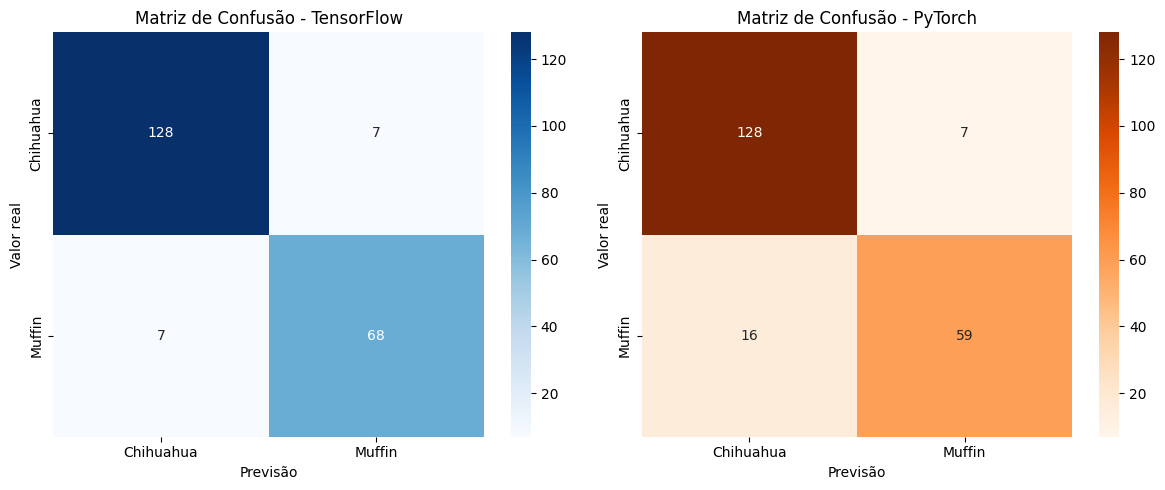

In [ ]:
# ==========================================
# 18. MATRIZES DE CONFUSÃO
# ==========================================

cm_tf = confusion_matrix(
    y_test,
    y_pred_tf,
    labels=[0, 1]
)

cm_pt = confusion_matrix(
    y_test,
    y_pred_pt,
    labels=[0, 1]
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    cm_tf,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=nomes_classes,
    yticklabels=nomes_classes,
    ax=axes[0]
)

axes[0].set_title('Matriz de Confusão - TensorFlow')
axes[0].set_xlabel('Previsão')
axes[0].set_ylabel('Valor real')

sns.heatmap(
    cm_pt,
    annot=True,
    fmt='d',
    cmap='Oranges',
    xticklabels=nomes_classes,
    yticklabels=nomes_classes,
    ax=axes[1]
)

axes[1].set_title('Matriz de Confusão - PyTorch')
axes[1].set_xlabel('Previsão')
axes[1].set_ylabel('Valor real')

plt.tight_layout()
plt.show()

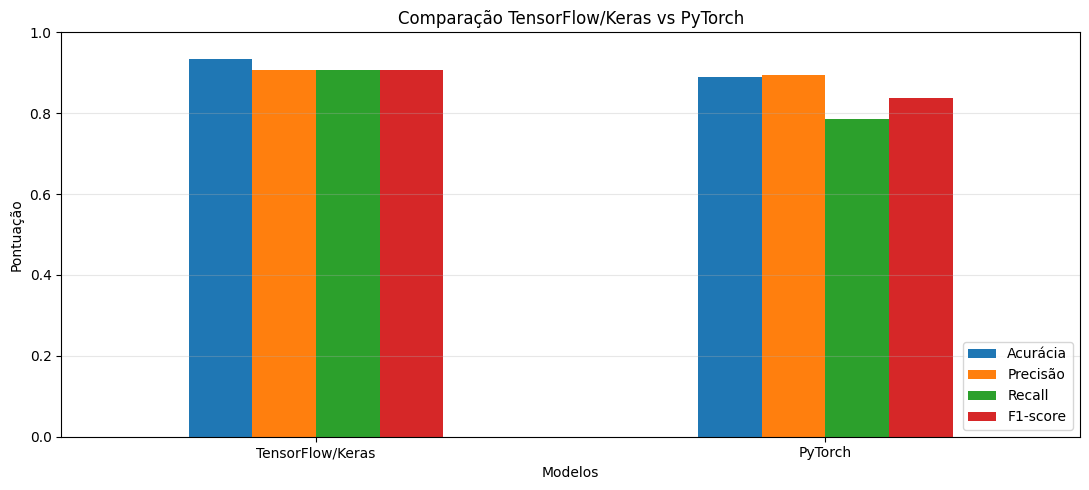

In [ ]:
# ==========================================
# 19. COMPARAÇÃO DE DESEMPENHO
# ==========================================

metricas = [
    'Acurácia',
    'Precisão',
    'Recall',
    'F1-score'
]

comparacao = tabela_resultados.set_index('Modelo')[metricas]

comparacao.plot(
    kind='bar',
    figsize=(11, 5),
    ylim=(0, 1),
    rot=0
)

plt.title('Comparação TensorFlow/Keras vs PyTorch')
plt.ylabel('Pontuação')
plt.xlabel('Modelos')
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 20. CLASSIFICAR IMAGEM DA INTERNET
# ==========================================

def classificar_imagem_internet(url):

    try:

        resposta = requests.get(
            url,
            timeout=20,
            headers={'User-Agent': 'Mozilla/5.0'}
        )

        resposta.raise_for_status()

        imagem = Image.open(
            BytesIO(resposta.content)
        ).convert('RGB')

        imagem_prep = imagem.resize((64, 64))

        imagem_array = (
            np.array(imagem_prep).astype('float32') / 255.0
        )

        imagem_tensor = np.expand_dims(
            imagem_array, axis=0
        )

        # TensorFlow
        pred_tf = model_tf.predict(
            imagem_tensor,
            verbose=0
        )[0][0]

        classe_tf = (
            'Muffin' if pred_tf >= 0.5 else 'Chihuahua'
        )

        confianca_tf = (
            pred_tf if pred_tf >= 0.5 else 1 - pred_tf
        ) * 100

        # PyTorch
        imagem_pt = transform(imagem).unsqueeze(0).to(device)

        model_pt.eval()

        with torch.no_grad():

            pred_pt = torch.sigmoid(
                model_pt(imagem_pt)
            ).item()

        classe_pt = (
            'Muffin' if pred_pt >= 0.5 else 'Chihuahua'
        )

        confianca_pt = (
            pred_pt if pred_pt >= 0.5 else 1 - pred_pt
        ) * 100

        # Exibição
        plt.figure(figsize=(6, 5))

        plt.imshow(imagem)

        plt.title(
            f"TensorFlow: {classe_tf} ({confianca_tf:.1f}%)\n"
            f"PyTorch: {classe_pt} ({confianca_pt:.1f}%)"
        )

        plt.axis('off')
        plt.show()

        print("RESULTADOS DA CLASSIFICAÇÃO")
        print("-" * 40)

        print(
            f"TensorFlow/Keras: {classe_tf} "
            f"({confianca_tf:.2f}%)"
        )

        print(
            f"PyTorch: {classe_pt} "
            f"({confianca_pt:.2f}%)"
        )

    except Exception as erro:

        print("Não foi possível classificar a imagem:", erro)

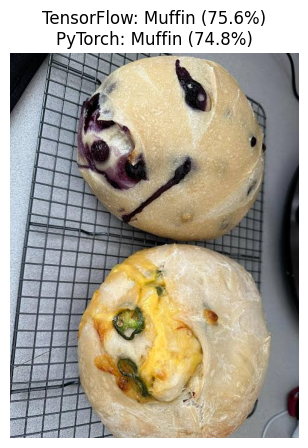

RESULTADOS DA CLASSIFICAÇÃO
----------------------------------------
TensorFlow/Keras: Muffin (75.63%)
PyTorch: Muffin (74.81%)


In [ ]:
url_imagem = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcT4sU6IjZ8mbL1iP5k3PvgNEQYalbxXvjSRR4LnK56QA3fUaIZ6v-yDlw5w&s=10"

classificar_imagem_internet(url_imagem)

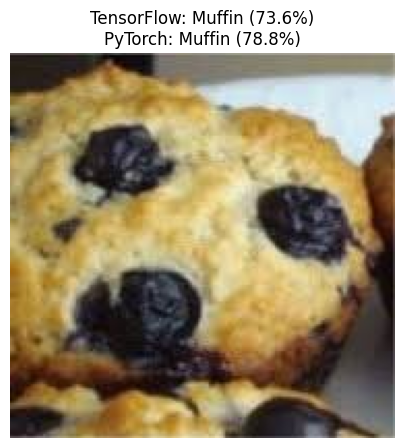

RESULTADOS DA CLASSIFICAÇÃO
----------------------------------------
TensorFlow/Keras: Muffin (73.64%)
PyTorch: Muffin (78.84%)


In [ ]:
url_imagem = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRsJFAKseyUwxl6iWMPgW5jlrN833JZ7HKrC9abzh2WuGLsmanT2cPdh-8C&s=10"

classificar_imagem_internet(url_imagem)

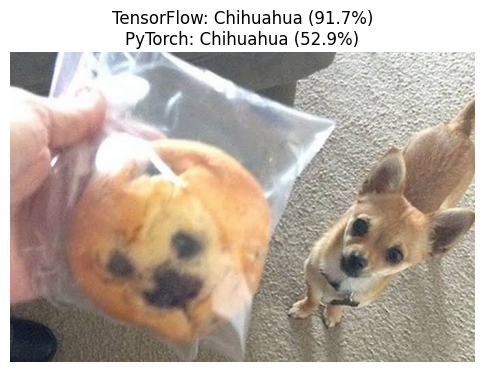

RESULTADOS DA CLASSIFICAÇÃO
----------------------------------------
TensorFlow/Keras: Chihuahua (91.68%)
PyTorch: Chihuahua (52.86%)


In [ ]:
url_imagem = "https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRCTEz4UWgupJ8juPaMKG3OMoa9WvqMlbkSo9rg8G7WthhTpe0m7osRGBY&s=10"

classificar_imagem_internet(url_imagem)

In [ ]:
# ==========================================
# 21. SALVAR OS MODELOS E RESULTADOS
# ==========================================

PASTA_RESULTADOS = os.path.join(
    BASE_DIR,
    'resultados'
)

os.makedirs(PASTA_RESULTADOS, exist_ok=True)

# Salvar TensorFlow
model_tf.save(
    os.path.join(
        PASTA_RESULTADOS,
        'modelo_chihuahua_muffin.keras'
    )
)

# Salvar PyTorch
torch.save(
    model_pt.state_dict(),
    os.path.join(
        PASTA_RESULTADOS,
        'modelo_chihuahua_muffin.pth'
    )
)

# Salvar métricas
tabela_resultados.to_csv(
    os.path.join(
        PASTA_RESULTADOS,
        'metricas_modelos.csv'
    ),
    index=False
)

print("Modelos e resultados salvos em:", PASTA_RESULTADOS)

Modelos e resultados salvos em: /content/drive/MyDrive/Sistemas Inteligentes/resultados


In [ ]:
# ==========================================
# 22. CONCLUSÃO AUTOMÁTICA
# ==========================================

melhor_modelo = tabela_resultados.loc[
    tabela_resultados['F1-score'].idxmax()
]

print("CONCLUSÃO DO EXPERIMENTO")
print("=" * 50)

print(
    f"O modelo com maior F1-score foi: "
    f"{melhor_modelo['Modelo']}."
)

print(
    f"Acurácia: {melhor_modelo['Acurácia']:.2%}"
)

print(
    f"Precisão: {melhor_modelo['Precisão']:.2%}"
)

print(
    f"Recall: {melhor_modelo['Recall']:.2%}"
)

print(
    f"F1-score: {melhor_modelo['F1-score']:.2%}"
)

print("\nOs dois modelos foram treinados e avaliados")
print("utilizando a mesma divisão dos dados.")

print(
    "\nA comparação permite analisar o desempenho "
    "das implementações em TensorFlow/Keras e PyTorch."
)

CONCLUSÃO DO EXPERIMENTO
O modelo com maior F1-score foi: TensorFlow/Keras.
Acurácia: 93.33%
Precisão: 90.67%
Recall: 90.67%
F1-score: 90.67%

Os dois modelos foram treinados e avaliados
utilizando a mesma divisão dos dados.

A comparação permite analisar o desempenho das implementações em TensorFlow/Keras e PyTorch.
